In [ ]:
!pip install nibabel

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip /content/drive/MyDrive/DATASET.zip

Archive:  /content/drive/MyDrive/DATASET.zip
   creating: DATASET/
   creating: DATASET/BraTS2020_TrainingData/
   creating: DATASET/BraTS2020_TrainingData/input_data_128/
   creating: DATASET/BraTS2020_TrainingData/input_data_128/train/
   creating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_0.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_1.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_10.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_101.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_102.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_103.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_104.npy  
  inflating: DATASET/BraTS2020_TrainingData/input_data_128/train/images/image_

In [ ]:
import shutil
shutil.rmtree('BraTS2020_ValidationData')

In [ ]:
import numpy as np
import nibabel as nib
import glob
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from tifffile import imsave
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

In [ ]:
TRAIN_DATASET_PATH = 'DATASET/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/'
#VALIDATION_DATASET_PATH = 'BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData'

test_image_flair=nib.load(TRAIN_DATASET_PATH + 'DATASET/BraTS20_Training_355/BraTS20_Training_355_flair.nii').get_fdata()
print(test_image_flair.max())
#Scalers are applied to 1D so let us reshape and then reshape back to original shape.
test_image_flair=scaler.fit_transform(test_image_flair.reshape(-1, test_image_flair.shape[-1])).reshape(test_image_flair.shape)

test_image_t1=nib.load(TRAIN_DATASET_PATH + 'DATASET/BraTS20_Training_355/BraTS20_Training_355_t1.nii').get_fdata()
test_image_t1=scaler.fit_transform(test_image_t1.reshape(-1, test_image_t1.shape[-1])).reshape(test_image_t1.shape)

test_image_t1ce=nib.load(TRAIN_DATASET_PATH + 'DATASET/BraTS20_Training_355/BraTS20_Training_355_t1ce.nii').get_fdata()
test_image_t1ce=scaler.fit_transform(test_image_t1ce.reshape(-1, test_image_t1ce.shape[-1])).reshape(test_image_t1ce.shape)

test_image_t2=nib.load(TRAIN_DATASET_PATH + 'DATASET/BraTS20_Training_355/BraTS20_Training_355_t2.nii').get_fdata()
test_image_t2=scaler.fit_transform(test_image_t2.reshape(-1, test_image_t2.shape[-1])).reshape(test_image_t2.shape)

print(test_image_t1.shape)

test_mask=nib.load(TRAIN_DATASET_PATH + 'DATASET/BraTS20_Training_355/BraTS20_Training_355_seg.nii').get_fdata()
test_mask=test_mask.astype(np.uint8)

print(np.unique(test_mask))  #0, 1, 2, 4 (Need to reencode to 0, 1, 2, 3)
test_mask[test_mask==4] = 3  #Reassign mask values 4 to 3
print(np.unique(test_mask))


FileNotFoundError: ignored

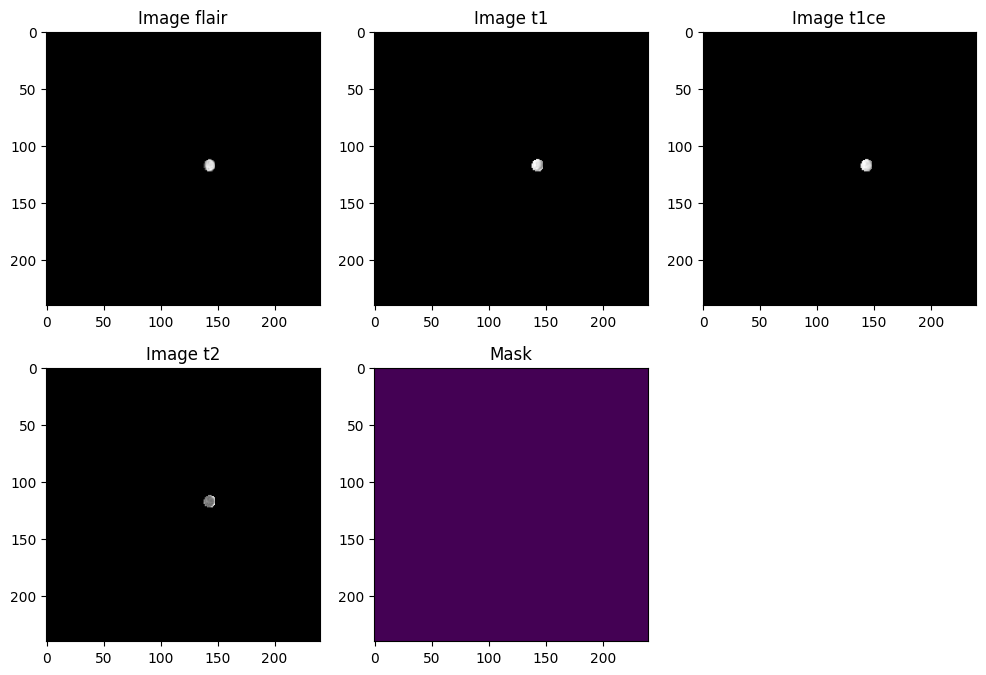

In [ ]:
n_slice=random.randint(0, test_mask.shape[2])
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.imshow(test_image_flair[:,:,n_slice], cmap='gray')
plt.title('Image flair')
plt.subplot(232)
plt.imshow(test_image_t1[:,:,n_slice], cmap='gray')
plt.title('Image t1')
plt.subplot(233)
plt.imshow(test_image_t1ce[:,:,n_slice], cmap='gray')
plt.title('Image t1ce')
plt.subplot(234)
plt.imshow(test_image_t2[:,:,n_slice], cmap='gray')
plt.title('Image t2')
plt.subplot(235)
plt.imshow(test_mask[:,:,n_slice])
plt.title('Mask')
plt.show()

In [ ]:
combined_x = np.stack([test_image_flair, test_image_t1ce, test_image_t2], axis=3)

In [ ]:
combined_x=combined_x[56:184, 56:184, 13:141] #Crop to 128x128x128x4
test_mask = test_mask[56:184, 56:184, 13:141]

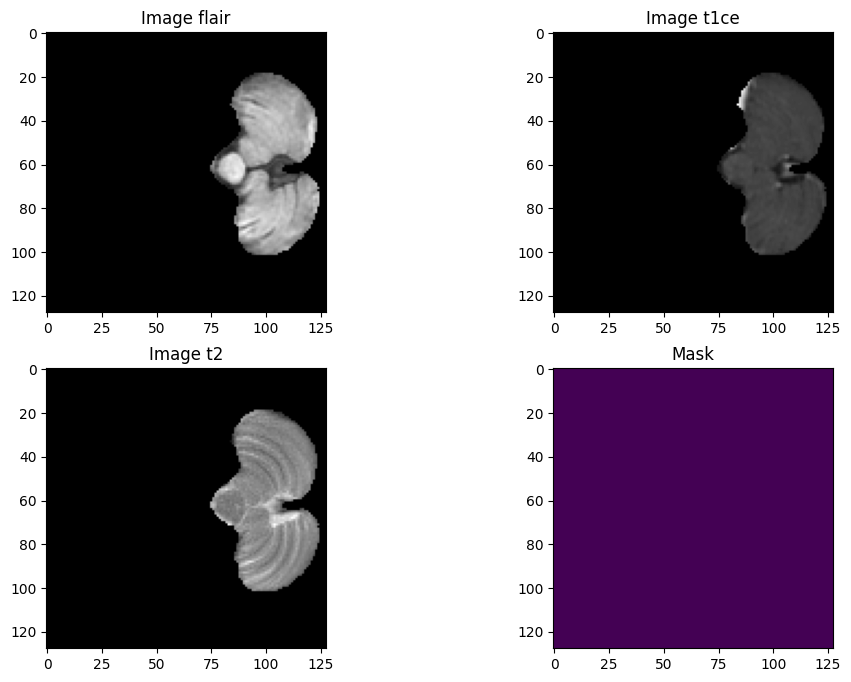

In [ ]:
n_slice=random.randint(0, test_mask.shape[2])
plt.figure(figsize=(12, 8))
plt.subplot(221)
plt.imshow(combined_x[:,:,n_slice, 0], cmap='gray')
plt.title('Image flair')
plt.subplot(222)
plt.imshow(combined_x[:,:,n_slice, 1], cmap='gray')
plt.title('Image t1ce')
plt.subplot(223)
plt.imshow(combined_x[:,:,n_slice, 2], cmap='gray')
plt.title('Image t2')
plt.subplot(224)
plt.imshow(test_mask[:,:,n_slice])
plt.title('Mask')
plt.show()


In [ ]:
# Saving it as a tif file and as a numpy array
imsave('BraTS2020_TrainingData/combined255.tif', combined_x)
np.save('BraTS2020_TrainingData/combined255.npy', combined_x)

<ipython-input-20-fb16a6d5bf96>:2: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave('BraTS2020_TrainingData/combined255.tif', combined_x)


In [ ]:
#Verify image is being read properly
#my_img=imread('BraTS2020_TrainingData/combined255.tif')
my_img=np.load('BraTS2020_TrainingData/combined255.npy')
print(combined_x == my_img.all())

[[[[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]

  [[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]

  [[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]

  ...

  [[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]

  [[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]

  [[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True  True  True]
   [ True  True  True]]]


 [[[ True  True  True]
   [ True  True  True]
   [ True  True  True]
   ...
   [ True  True  True]
   [ True 

In [ ]:
# Convert the mask to catagorical
test_mask = to_categorical(test_mask, num_classes=4)

In [ ]:
#t1_list = sorted(glob.glob('BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*/*t1.nii'))
t2_list = sorted(glob.glob('BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*/*t2.nii'))
t1ce_list = sorted(glob.glob('BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*/*t1ce.nii'))
flair_list = sorted(glob.glob('BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*/*flair.nii'))
mask_list = sorted(glob.glob('BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*/*seg.nii'))


In [ ]:
for img in range(len(t2_list)):   #Using t1_list as all lists are of same size
    print("Now preparing image and masks number: ", img)

    temp_image_t2=nib.load(t2_list[img]).get_fdata()
    temp_image_t2=scaler.fit_transform(temp_image_t2.reshape(-1, temp_image_t2.shape[-1])).reshape(temp_image_t2.shape)

    temp_image_t1ce=nib.load(t1ce_list[img]).get_fdata()
    temp_image_t1ce=scaler.fit_transform(temp_image_t1ce.reshape(-1, temp_image_t1ce.shape[-1])).reshape(temp_image_t1ce.shape)

    temp_image_flair=nib.load(flair_list[img]).get_fdata()
    temp_image_flair=scaler.fit_transform(temp_image_flair.reshape(-1, temp_image_flair.shape[-1])).reshape(temp_image_flair.shape)

    temp_mask=nib.load(mask_list[img]).get_fdata()
    temp_mask=temp_mask.astype(np.uint8)
    temp_mask[temp_mask==4] = 3  #Reassign mask values 4 to 3
    #print(np.unique(temp_mask))


    temp_combined_images = np.stack([temp_image_flair, temp_image_t1ce, temp_image_t2], axis=3)

    #Crop to a size to be divisible by 64 so we can later extract 64x64x64 patches.
    #cropping x, y, and z
    temp_combined_images=temp_combined_images[56:184, 56:184, 13:141]
    temp_mask = temp_mask[56:184, 56:184, 13:141]

    val, counts = np.unique(temp_mask, return_counts=True)

    if (1 - (counts[0]/counts.sum())) > 0.01:  #At least 1% useful volume with labels that are not 0
        print("Save Me")
        temp_mask= to_categorical(temp_mask, num_classes=4)
        np.save('BraTS2020_TrainingData/input_data_3channels/images/image_'+str(img)+'.npy', temp_combined_images)
        np.save('BraTS2020_TrainingData/input_data_3channels/masks/mask_'+str(img)+'.npy', temp_mask)

    else:
        print("I am useless")

Now preparing image and masks number:  0
Save Me
Now preparing image and masks number:  1
Save Me
Now preparing image and masks number:  2
Save Me
Now preparing image and masks number:  3
Save Me
Now preparing image and masks number:  4
I am useless
Now preparing image and masks number:  5
Save Me
Now preparing image and masks number:  6
Save Me
Now preparing image and masks number:  7
Save Me
Now preparing image and masks number:  8
Save Me
Now preparing image and masks number:  9
Save Me
Now preparing image and masks number:  10
Save Me
Now preparing image and masks number:  11
Save Me
Now preparing image and masks number:  12
Save Me
Now preparing image and masks number:  13
Save Me
Now preparing image and masks number:  14
Save Me
Now preparing image and masks number:  15
Save Me
Now preparing image and masks number:  16
Save Me
Now preparing image and masks number:  17
Save Me
Now preparing image and masks number:  18
Save Me
Now preparing image and masks number:  19
Save Me
Now p

OSError: ignored

In [ ]:
"""
Code for splitting folder into train, test, and val.
Once the new folders are created rename them and arrange in the format below to be used
for semantic segmentation using data generators.
"""
# !pip install split-folders
import splitfolders # or import split_folders
input_folder = 'DATASET/BraTS2020_TrainingData/input_data_3channels/'
output_folder = 'DATASET/BraTS2020_TrainingData/input_data_128/'
# Split with a ratio.
# To only split into training and validation set, set a tuple to `ratio`, i.e, `(.8, .2)`.
splitfolders.ratio(input_folder, output=output_folder, seed=42, ratio=(.90, .10), group_prefix=None)

Copying files: 688 files [06:24,  1.79 files/s]


In [ ]:
!pip install tfa-nightly

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_addons as tfa
# import numpy as np
import os
import shutil
from PIL import Image
import skimage.io as io
import skimage.transform as trans
import numpy as np
from tensorflow.keras.utils import img_to_array, array_to_img, load_img
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import *
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
# from tensorflow.keras import backend as keras
# from tensorflow.keras import layers
from random import sample
import matplotlib.pyplot as plt
# import tensorflow_addons as tfa
# from tensorflow import keras
#from tensorflow import keras
# import tensorflow as tf

/usr/local/lib/python3.9/dist-packages/tensorflow_addons/utils/ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.9.0 and strictly below 2.12.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.12.0 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an issue.
If you want to make sure you're using a tested and supported configuration, either change the TensorFlow version or the TensorFlow Addons's version. 
You can find the compatibility matrix in TensorFlow Addon's readme:
https://github.com/tensorflow/addons
  warnings.warn(


In [ ]:
num_classes = 4
input_shape = (128, 128, 128, 16)
learning_rate = 0.001
weight_decay = 0.0001
batch_size = 2
num_epochs = 1
image_size = 128  # We'll resize input images to this size
patch_size = 16  # Size of the patches to be extract from the input images
num_patches = image_size // patch_size
projection_dim = 96
latent_dim = 256
num_heads = 4
ffn_units= [
    projection_dim*2 ,
    projection_dim,
]  # Size of the transformer layers
num_transformer_blocks = 2

num_iterations = 2  # Repetitions of the cross-attention and Transformer modules.
classifier_units = [
    projection_dim,
    num_classes,
]  # Size of the Feedforward network of the final classifier.
dropout_rate = 0.03
print(f"Image size: {image_size} X {image_size} = {image_size ** 2}")
print(f"Patch size: {patch_size} X {patch_size} = {patch_size ** 2} ")
print(f"Patches per image: {num_patches}")
print(f"Elements per patch (3 channels): {(patch_size ** 2) * 3}")
print(f"Latent array shape: {latent_dim} X {projection_dim}")
print(f"Data array shape: {num_patches*num_patches*num_patches} X {projection_dim}")



# learning_rate = 0.001
# weight_decay = 0.0001
# batch_size = 64
# num_epochs = 50
# dropout_rate = 0.2
# image_size = 64  # We'll resize input images to this size.
# patch_size = 2  # Size of the patches to be extract from the input images.
# num_patches = (image_size // patch_size) ** 2  # Size of the data array.
# latent_dim = 256  # Size of the latent array.
# projection_dim = 256  # Embedding size of each element in the data and latent arrays.
# num_heads = 8  # Number of Transformer heads.
# ffn_units = [
#     projection_dim,
#     projection_dim,
# ]  # Size of the Transformer Feedforward network.
# num_transformer_blocks = 4
# num_iterations = 2  # Repetitions of the cross-attention and Transformer modules.
# classifier_units = [
#     projection_dim,
#     num_classes,
# ]  # Size of the Feedforward network of the final classifier.

# print(f"Image size: {image_size} X {image_size} = {image_size ** 2}")
# print(f"Patch size: {patch_size} X {patch_size} = {patch_size ** 2} ")
# print(f"Patches per image: {num_patches}")
# print(f"Elements per patch (3 channels): {(patch_size ** 2) * 3}")
# print(f"Latent array shape: {latent_dim} X {projection_dim}")
# print(f"Data array shape: {num_patches} X {projection_dim}")

Image size: 128 X 128 = 16384
Patch size: 16 X 16 = 256 
Patches per image: 8
Elements per patch (3 channels): 768
Latent array shape: 256 X 96
Data array shape: 512 X 96


In [ ]:
def create_ffn(hidden_units, dropout_rate):
    ffn_layers = []
    for units in hidden_units[:-1]:
        ffn_layers.append(layers.Dense(units, activation=tf.nn.gelu))

    ffn_layers.append(layers.Dense(units=hidden_units[-1]))
    ffn_layers.append(layers.Dropout(dropout_rate))

    ffn = keras.Sequential(ffn_layers)
    return ffn

In [ ]:
class Patches(keras.layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size
        self.patch_size_x = patch_size
        self.patch_size_y = patch_size
        self.patch_size_z = patch_size

    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'patch_size': self.patch_size,
            # "patch_size_x": self.patch_size_x,
            # "patch_size_y": self.patch_size_y,
            # "patch_size_z": self.patch_size_z,
        })
        return config

    def call(self, images):
        # print("images")
        # print(images.shape)

        batch_size = tf.shape(images)[0]
        images=tf.reshape(images,(batch_size,128,128,128,16))
        patches = tf.extract_volume_patches(
            input=images,
            ksizes=(1, self.patch_size_x, self.patch_size_y, self.patch_size_z, 1),
            strides=(1, self.patch_size_x, self.patch_size_y, self.patch_size_z, 1),
            padding="VALID",
            name=None
        )
        # print(patches.shape)
        # print(patches.type)
        patch_dim = patches.shape[-1]
        # print(patch_dim)

        patch_num = patches.shape[1]
        # print(patch_num)
        return tf.reshape(patches, (batch_size, patch_num * patch_num * patch_num, patch_dim))




In [ ]:

class PatchEncoder(tf.keras.layers.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.proj = tf.keras.layers.Dense(projection_dim)
        self.pos_embed = tf.keras.layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def get_config(self):
        config = super().get_config()
        config.update({
            'num_patches': self.num_patches,
            'projection_dim': self.projection_dim,
#             "proj": self.proj,
#             "pos_embed": self.pos_embed,
        })
        return config

    def call(self, patch):
        pos = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.proj(patch) + self.pos_embed(pos)


In [ ]:
def create_cross_attention_module(
    latent_dim, data_dim, projection_dim, ffn_units, dropout_rate
):

    inputs = {
        # Recieve the latent array as an input of shape [1, latent_dim, projection_dim].
        "latent_array": layers.Input(shape=(latent_dim, projection_dim)),
        # Recieve the data_array (encoded image) as an input of shape [batch_size, data_dim, projection_dim].
        "data_array": layers.Input(shape=(data_dim, projection_dim)),
    }

    # Apply layer norm to the inputs
    latent_array = layers.LayerNormalization(epsilon=1e-6)(inputs["latent_array"])
    data_array = layers.LayerNormalization(epsilon=1e-6)(inputs["data_array"])

    # Create query tensor: [1, latent_dim, projection_dim].
    query = layers.Dense(units=projection_dim)(latent_array)
    # Create key tensor: [batch_size, data_dim, projection_dim].
    key = layers.Dense(units=projection_dim)(data_array)
    # Create value tensor: [batch_size, data_dim, projection_dim].
    value = layers.Dense(units=projection_dim)(data_array)

    # Generate cross-attention outputs: [batch_size, latent_dim, projection_dim].
    attention_output = layers.Attention(use_scale=True, dropout=0.1)(
        [query, key, value], return_attention_scores=False
    )
    # Skip connection 1.
    attention_output = layers.Add()([attention_output, latent_array])

    # Apply layer norm.
    attention_output = layers.LayerNormalization(epsilon=1e-6)(attention_output)
    # Apply Feedforward network.
    ffn = create_ffn(hidden_units=ffn_units, dropout_rate=dropout_rate)
    outputs = ffn(attention_output)
    # Skip connection 2.
    outputs = layers.Add()([outputs, attention_output])

    # Create the Keras model.
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [ ]:
def create_transformer_module(
    latent_dim,
    projection_dim,
    num_heads,
    num_transformer_blocks,
    ffn_units,
    dropout_rate,
):

    # input_shape: [1, latent_dim, projection_dim]
    inputs = layers.Input(shape=(latent_dim, projection_dim))

    x0 = inputs
    # Create multiple layers of the Transformer block.
    for _ in range(num_transformer_blocks):
        # Apply layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=1e-6)(x0)
        # Create a multi-head self-attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        # Skip connection 1.
        x2 = layers.Add()([attention_output, x0])
        # Apply layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # Apply Feedforward network.
        ffn = create_ffn(hidden_units=ffn_units, dropout_rate=dropout_rate)
        x3 = ffn(x3)
        # Skip connection 2.
        x0 = layers.Add()([x3, x2])

    # Create the Keras model.
    model = keras.Model(inputs=inputs, outputs=x0)
    return model

In [ ]:
data_dim=512

In [ ]:
class Perceiver(keras.layers.Layer):
    def __init__(
        self,
        patch_size,
        data_dim,
        latent_dim,
        projection_dim,
        num_heads,
        num_transformer_blocks,
        ffn_units,
        dropout_rate,
        num_iterations,
        classifier_units,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.latent_dim = latent_dim
        self.data_dim = 512
        self.patch_size = patch_size
        self.projection_dim = projection_dim
        self.num_heads = num_heads
        self.num_transformer_blocks = num_transformer_blocks
        self.ffn_units = ffn_units
        self.dropout_rate = dropout_rate
        self.num_iterations = num_iterations
        self.classifier_units = classifier_units
    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'patch_size': self.patch_size,
            'latent_dim' : self.latent_dim,
            'data_dim':self.data_dim ,

            'projection_dim':self.projection_dim,
            'num_heads':self.num_heads,
            'num_transformer_blocks':self.num_transformer_blocks,
            'ffn_units':self.ffn_units,
            'dropout_rate':self.dropout_rate,
            'num_iterations':self.num_iterations,
           'classifier_units':self.classifier_units,
        })
        return config

    def build(self, input_shape):
        # Create latent array.
        self.latent_array = self.add_weight(
            shape=(self.latent_dim, self.projection_dim),
            initializer="random_normal",
            trainable=True,
        )

        # Create patching module.
#         self.patcher = Patches(self.patch_size)

        # Create patch encoder.
#         self.patch_encoder = PatchEncoder(self.data_dim, self.projection_dim)

        # Create cross-attenion module.
        self.cross_attention = create_cross_attention_module(
            self.latent_dim,
            self.data_dim,
            self.projection_dim,
            self.ffn_units,
            self.dropout_rate,
        )

        # Create Transformer module.
        self.transformer = create_transformer_module(
            self.latent_dim,
            self.projection_dim,
            self.num_heads,
            self.num_transformer_blocks,
            self.ffn_units,
            self.dropout_rate,
        )

        # Create global average pooling layer.
#         self.global_average_pooling = layers.GlobalAveragePooling1D()

        # Create a classification head.
#         self.classification_head = create_ffn(
#             hidden_units=self.classifier_units, dropout_rate=self.dropout_rate
#         )

        super().build(input_shape)

    def call(self, inputs):
        # Augment data.
#         inputs = layers.Input(shape=input_shape)
#         augmented = data_augmentation(inputs)
        # Create patches.
#         print(augmented.shape)
#         patches = self.patcher(augmented)
        # Encode patches.
#         print(patches.shape)
#         encoded_patches = self.patch_encoder(patches)
#         print(encoded_patches.shape)
        # Prepare cross-attention inputs.
        cross_attention_inputs = {
            "latent_array": tf.expand_dims(self.latent_array, 0),
            "data_array": inputs,
        }
#         return cross_attention_inputs
#         print(cross_attention_inputs )
        # Apply the cross-attention and the Transformer modules iteratively.
        for _ in range(self.num_iterations):
            # Apply cross-attention from the latent array to the data array.
            latent_array = self.cross_attention(cross_attention_inputs)
            # Apply self-attention Transformer to the latent array.
            latent_array = self.transformer(latent_array)
            # Set the latent array of the next iteration.
            cross_attention_inputs["latent_array"] = latent_array
#             print(latent_array.shape)
        return latent_array

        # Apply global average pooling to generate a [batch_size, projection_dim] repesentation tensor.
#         representation = self.global_average_pooling(latent_array)
# #         print(representation.shape)
#         # Generate logits.
#         logits = self.classification_head(representation)
#         model = keras.Model(inputs=inputs, outputs=logits)
#         return model
#         print(logits.shape)
#         return logits

In [ ]:
#from tifffile import imsave, imread
import os
import numpy as np
def load_img(img_dir, img_list):
    images=[]
    for i, image_name in enumerate(img_list):
        if (image_name.split('.')[1] == 'npy'):
            image = np.load(img_dir+image_name)
            images.append(image)
    images = np.array(images)
    return(images)

In [ ]:
def imageLoader(img_dir, img_list, mask_dir, mask_list, batch_size):
    L = len(img_list)
#keras needs the generator infinite, so we will use while true
    while True:
        batch_start = 0
        batch_end = batch_size
        while batch_start < L:
            limit = min(batch_end, L)
            X = load_img(img_dir, img_list[batch_start:limit])
            Y = load_img(mask_dir, mask_list[batch_start:limit])
            yield (X,Y) #a tuple with two numpy arrays with batch_size samples
            batch_start += batch_size
            batch_end += batch_size

In [ ]:
from matplotlib import pyplot as plt
import random
import numpy as np
train_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/images/"
train_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/masks/"
train_img_list=os.listdir(train_img_dir)
train_mask_list = os.listdir(train_mask_dir)
batch_size = 2
train_img_datagen = imageLoader(train_img_dir, train_img_list,
train_mask_dir, train_mask_list, batch_size)
#Verify generator.... In python 3 next() is renamed as __next__()
img, msk = train_img_datagen.__next__()
img_num = random.randint(0,img.shape[0]-1)
test_img=img[img_num]
test_mask=msk[img_num]
test_mask=np.argmax(test_mask, axis=3)

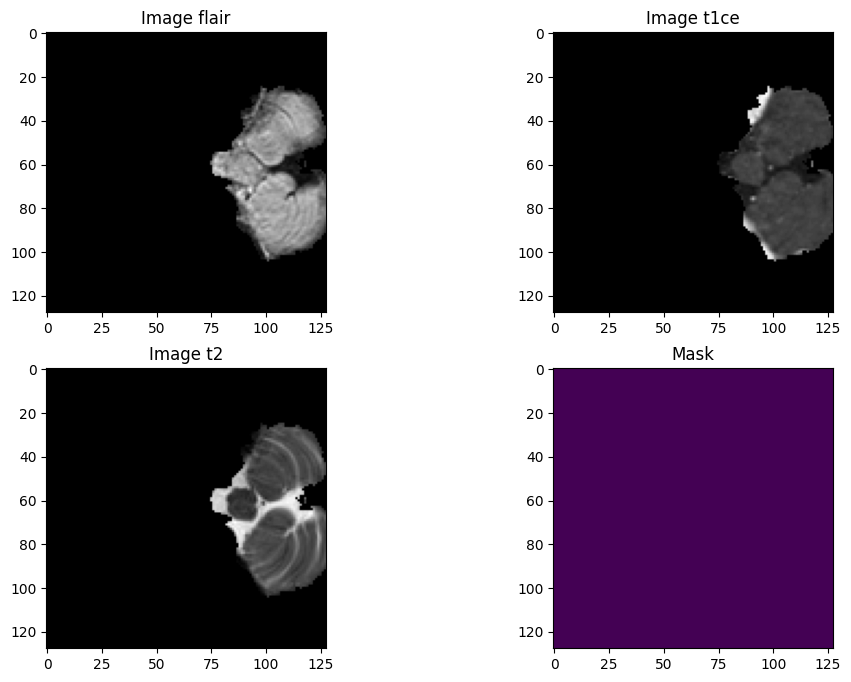

In [ ]:
n_slice=random.randint(0, test_mask.shape[2])
plt.figure(figsize=(12, 8))
plt.subplot(221)
plt.imshow(test_img[:,:,n_slice, 0], cmap='gray')
plt.title('Image flair')
plt.subplot(222)
plt.imshow(test_img[:,:,n_slice, 1], cmap='gray')
plt.title('Image t1ce')
plt.subplot(223)
plt.imshow(test_img[:,:,n_slice, 2], cmap='gray')
plt.title('Image t2')
plt.subplot(224)
plt.imshow(test_mask[:,:,n_slice])
plt.title('Mask')
plt.show()

In [ ]:
from keras.models import Model
from keras.layers import Input, Conv3D, MaxPooling3D, concatenate, Conv3DTranspose, BatchNormalization, Dropout, Lambda
from keras.optimizers import Adam
from keras.metrics import MeanIoU

kernel_initializer =  'he_uniform' #Try others if you want


################################################################
def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_DEPTH, IMG_CHANNELS, num_classes):
#Build the model
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_DEPTH, IMG_CHANNELS))
    #s = Lambda(lambda x: x / 255)(inputs)   #No need for this if we normalize our inputs beforehand
    s = inputs
    # print(s.shape)

    #Contraction path
    c1 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(s)
    c1 = Dropout(0.1)(c1)
    c1 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c1)
    p1 = MaxPooling3D((2, 2, 2))(c1)

    c2 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p1)
    c2 = Dropout(0.1)(c2)
    c2 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c2)
    p2 = MaxPooling3D((2, 2, 2))(c2)

    c3 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c3)
    p3 = MaxPooling3D((2, 2, 2))(c3)

    c4 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c4)
    p4 = MaxPooling3D(pool_size=(2, 2, 2))(c4)

    c5 = Conv3D(256, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv3D(256, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c5)

    #Expansive path
    u6 = Conv3DTranspose(128, (2, 2, 2), strides=(2, 2, 2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u6)
    c6 = Dropout(0.2)(c6)
    c6 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c6)

    u7 = Conv3DTranspose(64, (2, 2, 2), strides=(2, 2, 2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u7)
    c7 = Dropout(0.2)(c7)
    c7 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c7)

    u8 = Conv3DTranspose(32, (2, 2, 2), strides=(2, 2, 2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u8)
    c8 = Dropout(0.1)(c8)
    c8 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c8)

    u9 = Conv3DTranspose(16, (2, 2, 2), strides=(2, 2, 2), padding='same')(c8)

    patches = Patches(patch_size)(c1)
    # print(f"Patches -> {patches.shape}")
    encoded_patches = PatchEncoder(num_patches*num_patches*num_patches, projection_dim)(patches)
    # print(encoded_patches.shape)
    x=Perceiver(
    patch_size,
    num_patches,
    latent_dim,
    projection_dim,
    num_heads,
    num_transformer_blocks,
    ffn_units,
    dropout_rate,
    num_iterations,
    classifier_units,
    )(encoded_patches)
    # print(x.shape)
    x= tf.keras.layers.Dense(131072, activation="relu")(x)
#     print(x.shape)
    x=tf.reshape(x,shape=(-1,128,128,128,16))
    # print(x.shape)
    u9 = concatenate([u9, x])
    c9 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u9)
    c9 = Dropout(0.1)(c9)
    c9 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c9)

    outputs = Conv3D(num_classes, (1, 1, 1), activation='softmax')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    #compile model outside of this function to make it flexible.
#     model.summary()

    return model

#Test if everything is working ok.
model = simple_unet_model(128, 128, 128, 3, 4)
print(model.input_shape)
print(model.output_shape)

(None, 128, 128, 128, 3)
(None, 128, 128, 128, 4)


In [ ]:
import os
import numpy as np
# from custom_datagen import imageLoader
#import tensorflow as tf
import keras
from matplotlib import pyplot as plt
import glob
import random

In [ ]:
train_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/images/"
train_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/masks/"
img_list = os.listdir(train_img_dir)
msk_list = os.listdir(train_mask_dir)
num_images = len(os.listdir(train_img_dir))
img_num = random.randint(0,num_images-1)
test_img = np.load(train_img_dir+img_list[img_num])
test_mask = np.load(train_mask_dir+msk_list[img_num])
test_mask = np.argmax(test_mask, axis=3)

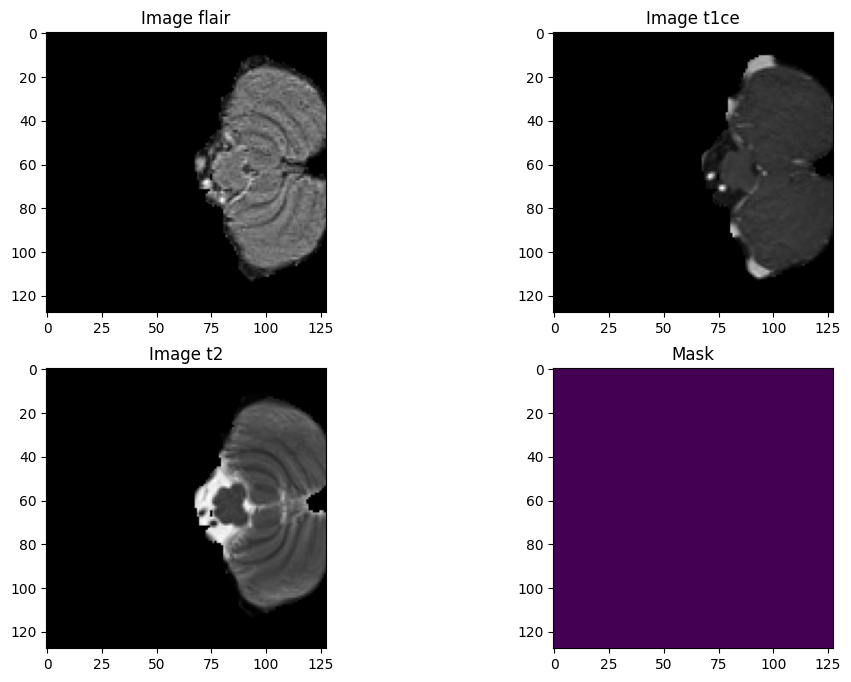

In [ ]:
n_slice=random.randint(0, test_mask.shape[2])
plt.figure(figsize=(12, 8))
plt.subplot(221)
plt.imshow(test_img[:,:,n_slice, 0], cmap='gray')
plt.title('Image flair')
plt.subplot(222)
plt.imshow(test_img[:,:,n_slice, 1], cmap='gray')
plt.title('Image t1ce')
plt.subplot(223)
plt.imshow(test_img[:,:,n_slice, 2], cmap='gray')
plt.title('Image t2')
plt.subplot(224)
plt.imshow(test_mask[:,:,n_slice])
plt.title('Mask')
plt.show()

In [ ]:
import pandas as pd
columns = ['0','1', '2', '3']
df = pd.DataFrame(columns=columns)
train_mask_list = sorted(glob.glob('DATASET/BraTS2020_TrainingData/input_data_128/train/masks/*.npy'))
for img in range(len(train_mask_list)):
# print(img)
    temp_image=np.load(train_mask_list[img])
    temp_image = np.argmax(temp_image, axis=3)
    val, counts = np.unique(temp_image, return_counts=True)
    zipped = zip(columns, counts)
    conts_dict = dict(zipped)
    df = df.append(conts_dict, ignore_index=True)
label_0 = df['0'].sum()
label_1 = df['1'].sum()
label_2 = df['1'].sum()
label_3 = df['3'].sum()
total_labels = label_0 + label_1 + label_2 + label_3
n_classes = 4
#Class weights claculation: n_samples / (n_classes * n_samples_for_class)
wt0 = round((total_labels/(n_classes*label_0)), 2) #round to 2 decimals
wt1 = round((total_labels/(n_classes*label_1)), 2)
wt2 = round((total_labels/(n_classes*label_2)), 2)
wt3 = round((total_labels/(n_classes*label_3)), 2)
print(f"wt0 -> {wt0}")
print(f"wt1 -> {wt1}")
print(f"wt2 -> {wt2}")
print(f"wt3 -> {wt3}")

<ipython-input-125-b3f5febeaf92>:12: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(conts_dict, ignore_index=True)
<ipython-input-125-b3f5febeaf92>:12: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(conts_dict, ignore_index=True)
<ipython-input-125-b3f5febeaf92>:12: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(conts_dict, ignore_index=True)
<ipython-input-125-b3f5febeaf92>:12: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(conts_dict, ignore_index=True)
<ipython-input-125-b3f5febeaf92>:12: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a f

KeyboardInterrupt: ignored

In [ ]:
wt0=0.26
wt1=22.62
wt2=22.62
wt3=26.33

In [ ]:
train_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/images/"
train_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/masks/"
val_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/val/images/"
val_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/val/masks/"
train_img_list=os.listdir(train_img_dir)
train_mask_list = os.listdir(train_mask_dir)
val_img_list=os.listdir(val_img_dir)
val_mask_list = os.listdir(val_mask_dir)

In [ ]:
batch_size = 2
train_img_datagen = imageLoader(train_img_dir, train_img_list,
train_mask_dir, train_mask_list, batch_size)
val_img_datagen = imageLoader(val_img_dir, val_img_list,
val_mask_dir, val_mask_list, batch_size)
#Verify generator.... In python 3 next() is renamed as __next__()
img, msk = train_img_datagen.__next__()
img_num = random.randint(0,img.shape[0]-1)
test_img=img[img_num]
test_mask=msk[img_num]
test_mask=np.argmax(test_mask, axis=3)

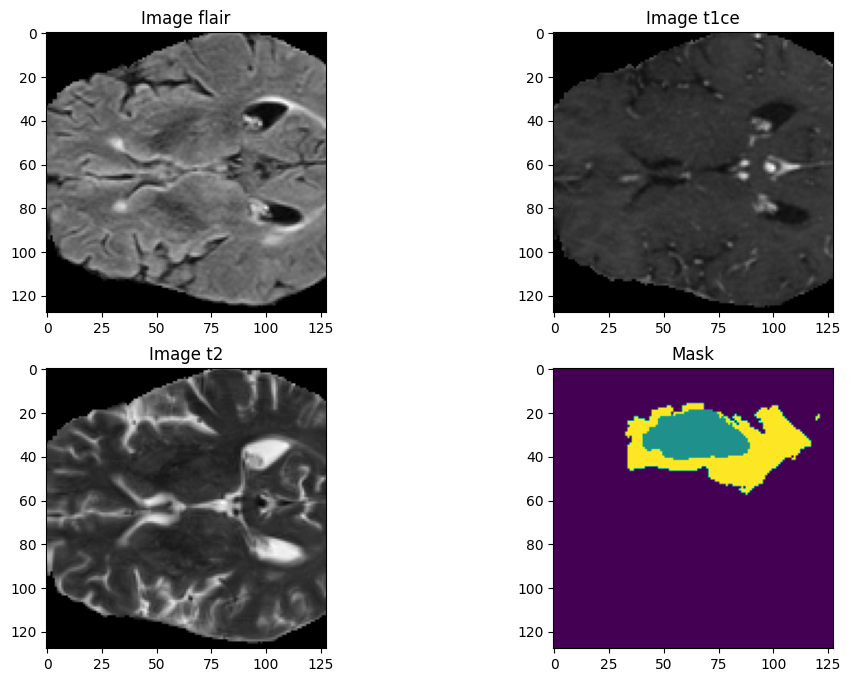

In [ ]:
n_slice=random.randint(0, test_mask.shape[2])
plt.figure(figsize=(12, 8))
plt.subplot(221)
plt.imshow(test_img[:,:,n_slice, 0], cmap='gray')
plt.title('Image flair')
plt.subplot(222)
plt.imshow(test_img[:,:,n_slice, 1], cmap='gray')
plt.title('Image t1ce')
plt.subplot(223)
plt.imshow(test_img[:,:,n_slice, 2], cmap='gray')
plt.title('Image t2')
plt.subplot(224)
plt.imshow(test_mask[:,:,n_slice])
plt.title('Mask')
plt.show()


In [ ]:
!pip install segmentation_models_3D

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 KB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 KB 7.4 MB/s eta 0:00:00


In [ ]:
import segmentation_models_3D as sm
dice_loss = sm.losses.DiceLoss(class_weights=np.array([wt0, wt1, wt2, wt3]))
# focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss
# + (1 * focal_loss)
metrics = ['accuracy', sm.metrics.IOUScore(threshold=0.5)]
LR = 0.0001
optim = keras.optimizers.Adam(LR)

In [ ]:
steps_per_epoch = len(train_img_list)//batch_size
val_steps_per_epoch = len(val_img_list)//batch_size
# from simple_3d_unet import simple_unet_model

model = simple_unet_model(128,128,128,3,4)


In [ ]:
model.compile(optimizer = keras.optimizers.Adam(LR) ,loss=total_loss, metrics=metrics)
print(model.summary())
print(model.input_shape)
print(model.output_shape)

Model: "model_9"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_37 (InputLayer)          [(None, 128, 128, 1  0           []                               
                                28, 3)]                                                           
                                                                                                  
 conv3d_171 (Conv3D)            (None, 128, 128, 12  1312        ['input_37[0][0]']               
                                8, 16)                                                            
                                                                                                  
 dropout_81 (Dropout)           (None, 128, 128, 12  0           ['conv3d_171[0][0]']             
                                8, 16)                                                      

In [ ]:
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=30,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch,
          )

# model.save('/content/drive/MyDrive/Colab Notebooks/Model/brats_3d_unet1.h5')


Epoch 1/30
154/154 [==============================] - 259s 2s/step - loss: -0.0547 - accuracy: 0.6830 - iou_score: 0.1700 - val_loss: -0.2143 - val_accuracy: 0.6835 - val_iou_score: 0.1995
Epoch 2/30
154/154 [==============================] - 235s 2s/step - loss: -0.3553 - accuracy: 0.7981 - iou_score: 0.2313 - val_loss: -0.3358 - val_accuracy: 0.8157 - val_iou_score: 0.2353
Epoch 3/30
 53/154 [=========>....................] - ETA: 2:19 - loss: -0.3327 - accuracy: 0.8034 - iou_score: 0.2321

KeyboardInterrupt: ignored

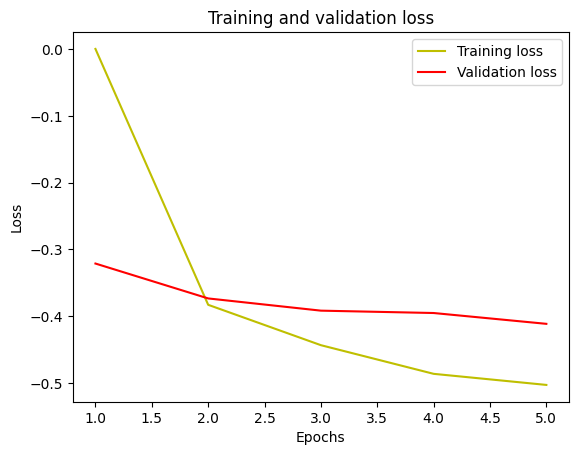

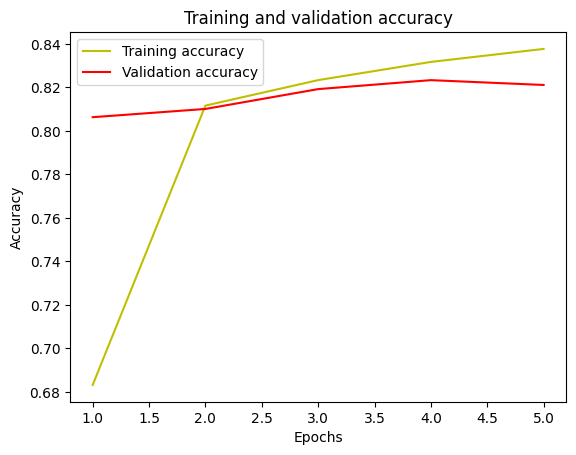

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.plot(epochs, acc, 'y', label='Training accuracy')
plt.plot(epochs, val_acc, 'r', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

1/1 [==============================] - 21s 21s/step
Mean IoU = 0.24298823


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

1/1 [==============================] - 1s 947ms/step
Mean IoU = 0.24236995


In [ ]:
img_num = 70

test_img = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]


1/1 [==============================] - 0s 116ms/step


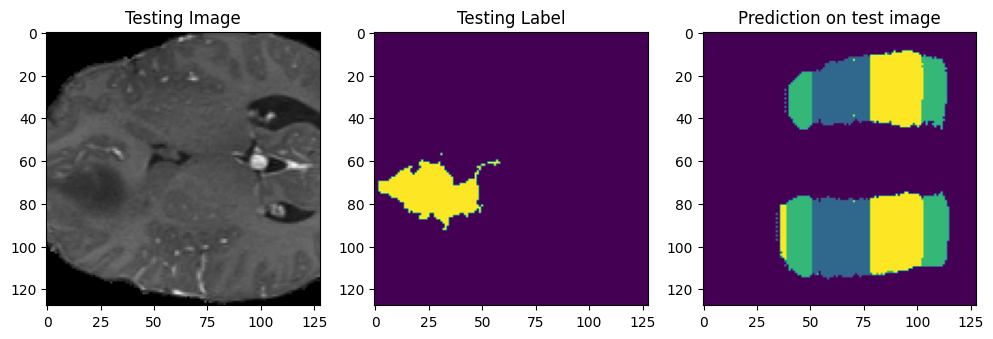

In [ ]:
from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

1/1 [==============================] - 0s 167ms/step


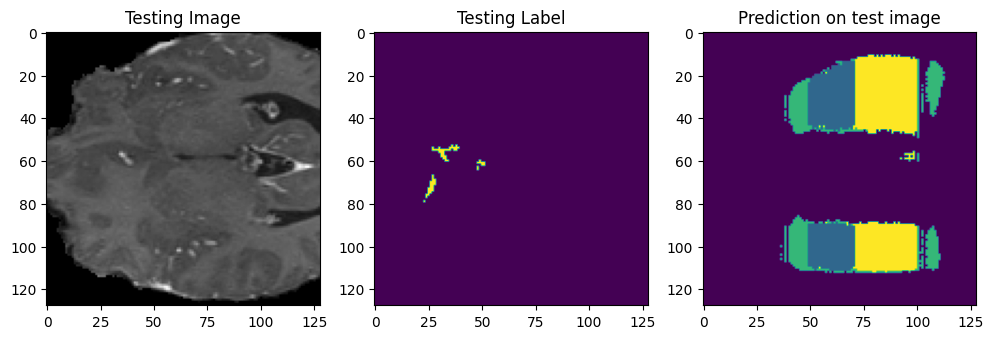

In [ ]:
from matplotlib import pyplot as plt
import random


img_num = 70

test_img = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

n_slice = 50
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

In [ ]:
from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())


AUC = 0.5


In [ ]:
import tensorflow as tf

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("Precesion =", pre.result().numpy())


Precesion = 0.4805975


In [ ]:
recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("Recall =", recall.result().numpy())


Recall = 0.13663192


In [ ]:
True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("true positive =", True_pos.result().numpy())

true positive = 340945.0


In [ ]:
True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("true negative =", True_neg.result().numpy())

true negative = 13913388.0


In [ ]:
False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("false positive =", False_pos.result().numpy())

false positive = 368474.0


In [ ]:
False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)

print("false negative =", False_neg.result().numpy())

false negative = 2154409.0


In [ ]:
F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

F1 score = 0.21277327915479


In [ ]:
t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

pixel accuracy =  0.84962445


In [ ]:
jac = F1_score/(2-F1_score)

print("jaccard index = ", jac)

jaccard index =  0.11905220343514442


In [ ]:
tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)

neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den

print("ARI(adjusted rand index) = ", ari)

ARI(adjusted rand index) =  0.12849305363620034


In [ ]:
tpr=tp/(tp+fn)
fpr=fp/(fp+tn)

print("tpr = ", tpr)
print("fpr = ", fpr)

tpr =  0.13663192
fpr =  0.025800137


In [ ]:
spec=tn/(tn+fp)
print(spec)

0.9741999


In [ ]:
ppv=tp/(tp+fp)

print(ppv)

0.4805975


In [ ]:
npv=tn/(fn+tn)
print(npv)

0.86591756


In [ ]:
from keras.models import load_model
new_model=load_model('/content/drive/MyDrive/Colab Notebooks/Model/brats_3d_unet3.h5',custom_objects={'Patches': Patches,'PatchEncoder':PatchEncoder})

TypeError: ignored

In [ ]:
from sklearn import metrics

y_true = []
y_pred = []

test_img_dir="DATASET/BraTS2020_TrainingData/input_data_128/val/images"
test_seg_dir="DATASET/BraTS2020_TrainingData/input_data_128/val/masks"
for img in os.listdir(test_img_dir):

#     print(img)
    num=img.split(".")[0].split("_")[-1]
#     print(num)
    test_img = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/images/"+str(img)+"")

    test_mask = np.load("DATASET/BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(num)+".npy")

    test_mask_argmax=np.argmax( test_mask, axis=0)

    test_img_input = np.expand_dims(test_img, axis=0)
    pred = model.predict(test_img_input)
# #         pred = model(img)  # get prediction for each pixel in the image
    y_true.append(test_mask.flatten())  # flatten all targets
    y_pred.append(pred.flatten())  # flatten all predictions

# concatenate all predictions and targets:
y_true = np.concatenate(y_true, axis=0)
y_pred = np.concatenate(y_pred, axis=0)
# copte the ROC curve
frp, trp, thresholds = metrics.roc_curve(y_true, y_pred)

1/1 [==============================] - 0s 128ms/step


In [ ]:
import sklearn
from sklearn.metrics import roc_curve, auc

roc_auc = auc(frp,trp)
plt.plot(frp,trp,label="ROC curve, AUC= "+str(roc_auc))
plt.plot([0,1], [0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()

NameError: ignored